# Hälsostudie – Del 2

## 1. Kodstruktur och beskrivande statistik

I denna del har analyskoden från Del 1 organiserats i återanvändbara funktioner, moduler och en klass. Syftet är att skapa en tydligare kodstruktur, minska upprepningar och göra analyserna enklare att vidareutveckla.

Modulen `src/analysis.py` innehåller funktioner för datakontroll, beskrivande statistik, konfidensintervall och hypotesprövning. Klassen `HealthAnalyzer` i `src/health_analyzer.py` använder dessa funktioner och innehåller även metoder för linjär regression, multipel regression och visualiseringar.

Genom att separera beräkningarna från notebooken kan samma kod återanvändas i flera analyser. Den beskrivande statistiken ger samma resultat som i Del 1, vilket visar att omstruktureringen inte har förändrat dessa beräkningar.

In [1]:

import sys
from pathlib import Path
import pandas as pd

# Hitta egna Python-filer
sys.path.insert(0, str(Path.cwd().parent / "src"))

from health_analyzer import HealthAnalyzer

# Läs in data
df = pd.read_csv("../data/health_study_dataset.csv")

# Skapa objekt och visa statistik
health = HealthAnalyzer(df)
health.get_stats()

,mean,median,min,max
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


### Återanvändning av analyser från Del 1

Utöver den beskrivande statistiken har även datakontroll, konfidensintervall och hypotesprövning organiserats i återanvändbara metoder i klassen `HealthAnalyzer`.

Detta gör det möjligt att utföra analyserna direkt genom klassens objekt, utan att behöva upprepa beräkningarna i notebooken.

In [2]:
health.get_data_info()
health.get_confidence_intervals()
health.get_hypothesis_test()


DATAKONTROLL
────────────────────────────────────
Antal personer: 800
Antal kolumner: 9
Saknade värden: 0

KONFIDENSINTERVALL FÖR BLODTRYCK
────────────────────────────────────
Normalapproximation: 148.29–150.07 mmHg
Bootstrap:           148.31–150.05 mmHg

HYPOTESPRÖVNING: RÖKARE OCH BLODTRYCK
────────────────────────────────────
t-värde: 0.450
p-värde: 0.3264
Resultat: Kan inte förkasta nollhypotesen.


### Tolkning av resultaten

Datakontrollen visar att datasetet innehåller 800 observationer och inga saknade värden.

De två metoderna för att beräkna 95 % konfidensintervall för det genomsnittliga systoliska blodtrycket ger mycket liknande resultat. Normalapproximationen ger intervallet 148,29–150,07 mmHg och bootstrap ger 148,31–150,05 mmHg.

Hypotesprövningen undersöker om rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare. Eftersom p-värdet (0,3264) är större än signifikansnivån 0,05 kan nollhypotesen inte förkastas. Resultatet ger därmed inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck i detta dataset.

## 2. Linjär regression och sambandet mellan ålder och blodtryck

För att undersöka sambandet mellan ålder och systoliskt blodtryck används enkel linjär regression med NumPy.

Ålder är den **oberoende variabeln (X)** och systoliskt blodtryck är den **beroende variabeln (Y)**. Med hjälp av minsta kvadratmetoden beräknas en regressionslinje som beskriver det linjära sambandet mellan variablerna.

Regressionslinjens **lutningskoefficient** visar hur mycket det förväntade blodtrycket förändras när åldern ökar med ett år. **Interceptet** anger linjens förväntade blodtryck vid åldern noll år.


ENKEL LINJÄR REGRESSION
────────────────────────────────────
Intercept:                  122.68
Ålderns koefficient:        0.54
Förklaringsgrad (R²):       0.369


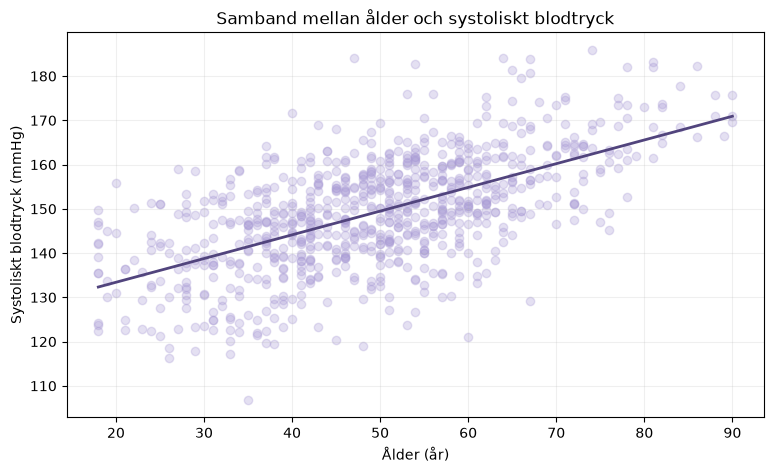

In [3]:
# Sparar regressionsresultaten för att kunna jämföra modellerna senare.
slope, intercept, r2_simple = health.get_regression_results()
health.plot_regression()

### Resultat och tolkning

Den linjära regressionen visar ett positivt samband mellan ålder och systoliskt blodtryck.

**Lutningskoefficienten är 0,54**, vilket innebär att det förväntade systoliska blodtrycket ökar med ungefär 0,54 mmHg för varje år som åldern ökar, enligt modellen.

**Interceptet är 122,68 mmHg** och anger det förväntade blodtrycket vid 0 års ålder. Eftersom undersökningen gäller vuxna är interceptet främst ett matematiskt värde och har ingen praktisk betydelse i det här sammanhanget.

**Förklaringsgraden (R²) är 0,369**, vilket innebär att modellen förklarar ungefär 36,9 % av variationen i systoliskt blodtryck. Resterande variation förklaras inte av modellen och kan bero på andra faktorer.

Resultatet tyder på att ålder har ett samband med systoliskt blodtryck i datasetet, men att ålder ensam inte räcker för att förklara alla skillnader. Regressionen visar ett statistiskt samband, inte att ålder i sig har bevisats orsaka förändringen.

## 3. Residualanalys

För att undersöka hur väl den linjära regressionsmodellen passar våra data görs en residualanalys.

En **residual** är skillnaden mellan ett observerat värde och det värde som modellen förutsäger:

$
e_i = y_i - \hat{y}_i
$

I residualdiagrammet visas residualerna i förhållande till de förutsagda blodtrycksvärdena.

Om residualerna är slumpmässigt fördelade runt noll utan något tydligt mönster talar det för att en linjär modell är rimlig. Tydliga mönster kan däremot tyda på att modellen inte fångar sambandet tillräckligt väl.

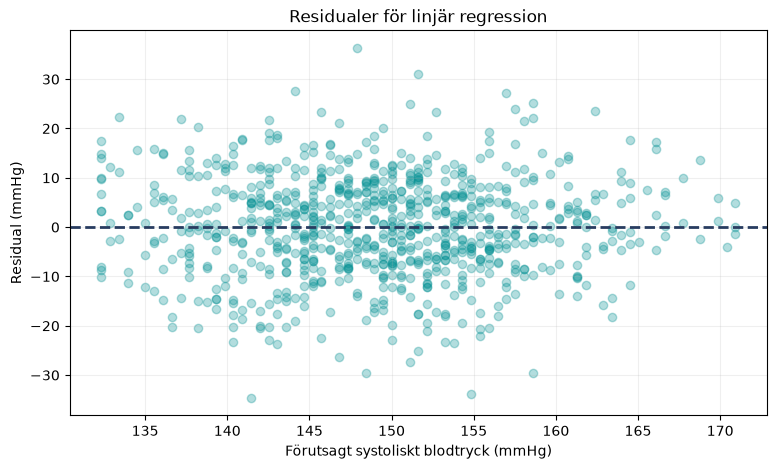

In [4]:
health.plot_residuals()

### Resultat och tolkning

Residualdiagrammet visar att residualerna är spridda på båda sidor om nollinjen utan något tydligt systematiskt mönster. Spridningen verkar också vara relativt jämn över de förutsagda blodtrycksvärdena.

Detta är förenligt med antagandet om **homoskedasticitet**, vilket innebär att residualernas varians är ungefär konstant. Det tyder på att en linjär regressionsmodell är rimlig för datasetet. Samtidigt finns det relativt stora avvikelser mellan observerade och förutsagda värden.

Tillsammans med förklaringsgraden på 36,9 % visar residualanalysen att ålder har ett tydligt linjärt samband med systoliskt blodtryck, men att modellen inte fångar all variation i blodtrycket.

Residualdiagrammet ger stöd för modellens lämplighet, men kan inte ensamt bekräfta att alla regressionsantaganden är uppfyllda.

## 4. Multipel linjär regression

För att undersöka om fler variabler kan förklara variationen i systoliskt blodtryck används **multipel linjär regression** med NumPy.

Till skillnad från den enkla linjära regressionen, där endast ålder användes, ingår nu både **ålder och vikt som oberoende variabler (X)**. Systoliskt blodtryck är fortfarande den **beroende variabeln (Y)**.

Regressionskoefficienterna beräknas med **minsta kvadratmetoden** genom `np.linalg.lstsq()`, som använder matrisberäkningar för att hitta den modell som minimerar summan av de kvadrerade residualerna.

Genom att jämföra modellernas **förklaringsgrad (R²)** kan vi undersöka om vikt bidrar till att förklara ytterligare variation i blodtrycket utöver ålder.


In [5]:
# Sparar koefficienter och R² för jämförelse med den enkla regressionen.
coefficients, r2_multiple = health.multiple_regression()


MULTIPEL LINJÄR REGRESSION
────────────────────────────────────
Intercept:                  109.50
Ålderns koefficient:        0.54
Viktens koefficient:        0.18
Förklaringsgrad (R²):       0.405


### Resultat och tolkning

Den multipla regressionen visar att både ålder och vikt har positiva regressionskoefficienter.

**Ålderns koefficient är 0,54**, vilket innebär att det förväntade systoliska blodtrycket ökar med ungefär 0,54 mmHg per extra år när vikten hålls konstant.

**Viktens koefficient är 0,18**, vilket innebär att det förväntade blodtrycket ökar med ungefär 0,18 mmHg per extra kilogram när åldern hålls konstant.

Modellens **förklaringsgrad (R²) är 0,405**, jämfört med 0,369 för den enkla regressionen. Det innebär att modellen med både ålder och vikt förklarar 40,5 % av variationen i blodtrycket, en ökning med 3,6 procentenheter.

Resultatet visar att vikt bidrar med ytterligare förklaringsvärde i datasetet. Förbättringen är dock relativt liten, och modellen lämnar fortfarande en stor del av variationen oförklarad.


### 4.1 Modelljämförelse – MAE och R² på testdata

För att undersöka hur väl regressionsmodellerna kan förutsäga systoliskt blodtryck delades datasetet upp i **80 % träningsdata och 20 % testdata**, vilket är en vanlig uppdelning vid modellutvärdering.
Modellerna tränades och utvärderades på samma uppdelning för att jämförelsen skulle bli rättvis.

**Val av utvärderingsmått**

Jag valde att använda MAE (Mean Absolute Error) eftersom måttet visar hur mycket modellens förutsägelser i genomsnitt avviker från de verkliga blodtrycksvärdena. Eftersom MAE anges i samma enhet som blodtrycket, mmHg, blir resultatet enkelt att tolka.

Jag använde även R² som ett kompletterande mått för att undersöka hur stor del av variationen i blodtrycket som modellerna kan förklara. 
För att få en bättre förståelse för MAE och R² använde jag även videon [Evaluation Metrics For Regression – When & Why To Use What](https://www.youtube.com/watch?v=TrzUlo4BImM) av NeuralNine.


In [6]:
model_results = health.compare_models()


MODELLJÄMFÖRELSE PÅ TESTDATA
────────────────────────────────────────────────
Modell                    MAE (mmHg)          R²
Enkel regression                7.75       0.395
Multipel regression             7.63       0.425


**Resultat och tolkning**

Den enkla regressionen, som endast använder ålder, fick ett MAE på 7,75 mmHg och ett R² på 0,395.

Den multipla regressionen, som använder både ålder och vikt, fick ett MAE på 7,63 mmHg och ett R² på 0,425.

Den multipla regressionen gav alltså något bättre förutsägelser på testdatan, med ett lägre genomsnittligt fel och en högre förklaringsgrad. Förbättringen var dock relativt liten, vilket tyder på att vikt tillför viss, men begränsad, information utöver ålder.

### 4.2 Samband mellan kolesterol och blodtryck

Jag ville också undersöka om kolesterol har något samband med
systoliskt blodtryck. Jag använder ett spridningsdiagram för att
se hur värdena fördelar sig och Pearsons korrelation för att
mäta hur starkt det linjära sambandet är.

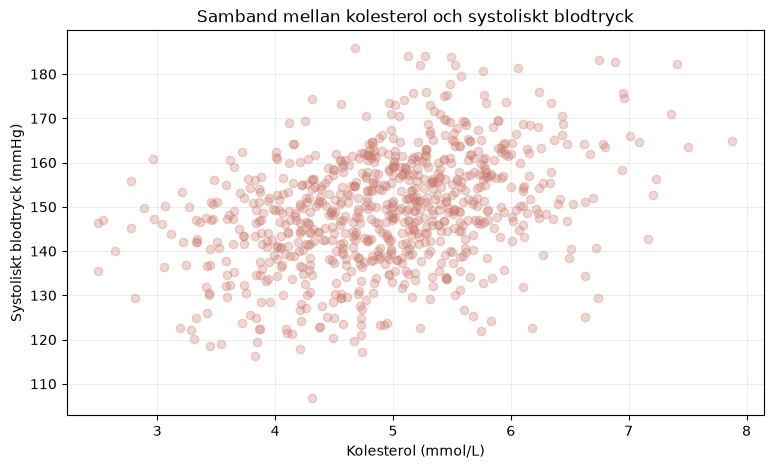

Pearsons korrelation (r): 0.368


In [7]:
health.plot_cholesterol_bp()

**Resultat och tolkning**

Pearsons korrelation blev 0,368, vilket visar ett måttligt positivt samband mellan kolesterol och systoliskt blodtryck.

I spridningsdiagrammet kan man se att blodtrycket generellt tenderar att öka med högre kolesterolvärden, men punkterna är ganska utspridda. Det betyder att sambandet finns, men att kolesterol inte ensamt kan förklara variationen i blodtryck.

Eftersom jag tidigare såg att ålder har ett samband med blodtrycket skulle det också vara intressant att undersöka hur mycket av sambandet med kolesterol som kan förklaras av ålder.

## 5. Diskussion och slutsats

Syftet med Del 2 var att vidareutveckla analysen från Del 1 genom att organisera koden i återanvändbara funktioner, moduler och en klass samt använda regressionsanalys för att undersöka sambandet mellan ålder, vikt och systoliskt blodtryck.

Genom att flytta datakontroll, beskrivande statistik, konfidensintervall och hypotesprövning till separata funktioner har koden blivit mer strukturerad och enklare att återanvända. Klassen `HealthAnalyzer` samlar dessa funktioner tillsammans med de nya regressionsanalyserna och visualiseringarna.

De återanvända analyserna visar att datasetet innehåller 800 observationer utan saknade värden. Konfidensintervallen för det genomsnittliga systoliska blodtrycket blev mycket lika med normalapproximation och bootstrap. Hypotesprövningen gav inget statistiskt signifikant stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare.

Den enkla linjära regressionen visade ett positivt samband mellan ålder och systoliskt blodtryck, där modellen förklarade 36,9 % av variationen. När vikt inkluderades i den multipla regressionen ökade förklaringsgraden till 40,5 %, vilket motsvarar en förbättring med 3,6 procentenheter.
Jag valde multipel regression eftersom metoden gör det möjligt att undersöka flera oberoende variabler i samma modell. Genom att använda NumPys matrisberäkningar kunde jag också tillämpa linjär algebra i en praktisk dataanalys.

Residualanalysen visade inget tydligt systematiskt mönster, vilket talar för att en linjär modell är rimlig. Samtidigt visar spridningen att modellerna inte förklarar all variation i blodtrycket.
För att undersöka modellernas prediktionsförmåga delade jag även upp datasetet i 80 % träningsdata och 20 % testdata. Den multipla regressionen hade både högre R² och lägre MAE på testdata än den enkla regressionen. Förbättringen var dock relativt liten, vilket visar att vikt bidrar med viss ytterligare information.

Analysen av kolesterol och systoliskt blodtryck visade ett måttligt positivt linjärt samband med en korrelationskoefficient på 0,368. Det skulle därför vara intressant att i en framtida analys även inkludera kolesterol som en variabel i den multipla regressionen.
En begränsning är att modellernas prediktionsförmåga endast har utvärderats med en uppdelning av datasetet. Korsvalidering eller utvärdering på ett oberoende dataset skulle kunna ge en bättre bild av hur väl modellerna fungerar för nya observationer. De observerade sambanden visar inte heller att variablerna orsakar förändringar i blodtrycket.

Sammanfattningsvis visar Del 2 hur analyskod kan återanvändas och vidareutvecklas med objektorienterad programmering. Den multipla regressionen gav både högre förklaringsgrad och något bättre prediktionsförmåga än den enkla modellen, men en betydande del av variationen i blodtrycket återstår att förklara.

## 6. Källor och referenser

Följande dokumentation och referenser har använts som stöd
för metodval, statistiska analyser och Python-beräkningar.


### Kursmaterial och kompletterande referenser

**MegansCreativeLabs (2026)**

- *Pythonprogrammering och statistisk dataanalys*  
  Egen sammanställd studiehandbok baserad på Joakims
  undervisning inom Data Science-utbildningen.
  Handboken innehåller teoretiska förklaringar,
  statistiska metoder, matematiska formler och praktiska
  kodexempel i Python.

  Materialet har använts som stöd för metodval,
  statistiska beräkningar och regressionsanalys.

  [GitHub – Pythonprogrammering och statistisk dataanalys](https://github.com/MegansCreativeLabs/data_science)

**NeuralNine (2024)**

- [Evaluation Metrics For Regression – When & Why To Use What](https://www.youtube.com/watch?v=TrzUlo4BImM)  
  YouTube – genomgång av utvärderingsmått för regressionsmodeller.

### NumPy

**NumPy Developers – officiell dokumentation**

- [numpy.polyfit](https://numpy.org/doc/stable/reference/generated/numpy.polyfit.html)  
  Polynomanpassning med minsta kvadratmetoden för enkel linjär regression.

- [numpy.linalg.lstsq](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html)  
  Minsta kvadratmetoden och matrisberäkningar för multipel linjär regression.



### Scikit-learn

**Scikit-learn Developers – officiell dokumentation**

- [LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)  
  Anpassning av linjära regressionsmodeller.

- [train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)  
  Uppdelning av datasetet i tränings- och testdata.

- [mean_absolute_error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html)  
  Beräkning av genomsnittligt absolut prediktionsfel (MAE).

- [r2_score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html)  
  Beräkning av modellens förklaringsgrad (R²).



### SciPy

**SciPy Developers – officiell dokumentation**

- [scipy.stats.ttest_ind](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html)  
  Oberoende t-test, Welchs t-test och ensidig hypotesprövning.



### Kompletterande utbildningsmaterial

**NeuralNine (2024)**

- [Evaluation Metrics For Regression – When & Why To Use What](https://www.youtube.com/watch?v=TrzUlo4BImM)  
  YouTube – genomgång av utvärderingsmått för regressionsmodeller.